In [3]:
import pandas as pd
import yaml 
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from decimal import Decimal
from datetime import datetime
from dateutil import parser
import networkx as nx

data exploration

In [4]:
df_users = pd.read_csv('users.csv')
df_users = pd.DataFrame(df_users)

df_books = yaml.safe_load(open('books.yaml'))
df_books = pd.DataFrame(df_books)

df_orders = pd.read_parquet('orders.parquet')

In [5]:
df_users.head()
len(df_users)
df_users.info()

df_users.duplicated().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3008 entries, 0 to 3007
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       3008 non-null   int64
 1   name     3008 non-null   str  
 2   address  2917 non-null   str  
 3   phone    3008 non-null   str  
 4   email    3008 non-null   str  
dtypes: int64(1), str(4)
memory usage: 413.9 KB


np.int64(0)

In [6]:
print(type(df_books))
df_books.info()
print(df_books.isna().sum(), "\n")
print(df_books.duplicated().sum())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 775 entries, 0 to 774
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   :id         775 non-null    int64 
 1   :title      775 non-null    str   
 2   :author     775 non-null    str   
 3   :genre      775 non-null    str   
 4   :publisher  767 non-null    str   
 5   :year       772 non-null    object
dtypes: int64(1), object(1), str(4)
memory usage: 88.6+ KB
:id           0
:title        0
:author       0
:genre        0
:publisher    8
:year         3
dtype: int64 

0


In [7]:
len(df_orders)
df_orders.info()
print(df_orders.isna().sum(), "\n")
print(df_orders.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10877 entries, 0 to 10876
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          10877 non-null  int64
 1   user_id     10877 non-null  int64
 2   book_id     10877 non-null  int64
 3   quantity    10877 non-null  int32
 4   unit_price  10877 non-null  str  
 5   timestamp   10877 non-null  str  
 6   shipping    8260 non-null   str  
dtypes: int32(1), int64(3), str(3)
memory usage: 985.9 KB
id               0
user_id          0
book_id          0
quantity         0
unit_price       0
timestamp        0
shipping      2617
dtype: int64 

0


In [8]:
print(df_users.isna().sum(), "\n")
print(df_users.duplicated().sum())



id          0
name        0
address    91
phone       0
email       0
dtype: int64 

0


data cleaning

In [9]:
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].unique(), "\n")
print(df_orders['timestamp'].head(20))

0      $30.25
1         $66
2      56.0 $
3    USD49.50
4     42.0USD
5    USD23.50
6      $54.75
7      €37¢25
8     € 43.00
9     46.75 $
Name: unit_price, dtype: str 

<ArrowStringArray>
[   '$30.25',       '$66',    '56.0 $',  'USD49.50',   '42.0USD',  'USD23.50',
    '$54.75',    '€37¢25',   '€ 43.00',   '46.75 $',
 ...
  'EUR 48.5', 'EUR 46.25',    '51.99$',      '$69.',  '45.25USD', 'USD 40.25',
    '73.25$', '18.25 USD',   '20.50 €',   '$ 55.00']
Length: 6279, dtype: str 

0            18:12:56 2025-09-07
1            2025-09-20T08:50:30
2           2026-04-06, 13:19:18
3            2025-08-20 00:08:24
4             07/20/26, 10:39:46
5        10:32:09 P.M., 09/11/25
6        05:04:50 A.M., 01/10/26
7          02/04/26, 11:31:25 pm
8     31-AUG-2025, 03:35:48 P.M.
9            2025-10-17T15:04:08
10      2025-12-09,03:04:37 A.M.
11       2026-06-21T01:12:19.654
12             2026-02-02, 21:28
13       2026-03-02T10:16:48.141
14              12:50 2025-06-02
15              202

In [10]:
print(df_books[':year'].unique()[:20], "\n")

[2003 1987 2020 2019 2025 1981 1995 1992 2010 2004 2000 1984 2018 2026
 1844 1982 1999 2006 2011 2005] 



In [11]:
#function to change currency to usd and clean signs such as $ or eur

def convert_to_usd(unit_price):
    clean_price = unit_price.replace("$", "").replace("EUR", "").replace("€", "").replace("USD", "").replace("¢", ".").strip()
   
    if "€" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("€", ".").replace("¢", "")
        return Decimal(clean_price) * Decimal("1.2")

    if "$" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("$", ".").replace("¢", "")
        return Decimal(clean_price)
    value = Decimal(clean_price)
    if "EUR" in unit_price or "€" in unit_price:
        currency = value * Decimal("1.2")
    elif "$" in unit_price or "USD" in unit_price:
        currency = value
    else:
        raise ValueError("Unsupported currency")
    
    return currency

In [12]:
print(convert_to_usd("EUR72.75"))  # test

87.300


In [13]:
df_orders['unit_price'] = df_orders['unit_price'].apply(convert_to_usd)
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].isna().sum())

0      30.25
1         66
2       56.0
3      49.50
4       42.0
5      23.50
6      54.75
7    0.44700
8     51.600
9      46.75
Name: unit_price, dtype: object 

0


In [14]:
#paid price = quentity * unit_price
df_orders['paid_price'] = df_orders['quantity'] * df_orders['unit_price']
print(df_orders[['quantity', 'unit_price', 'paid_price']].head(20))


    quantity unit_price paid_price
0          1      30.25      30.25
1          1         66         66
2          1       56.0       56.0
3          1      49.50      49.50
4          1       42.0       42.0
5          1      23.50      23.50
6          1      54.75      54.75
7          1    0.44700    0.44700
8          3     51.600    154.800
9          1      46.75      46.75
10         1       19.0       19.0
11         1     38.100     38.100
12         2       70.5      141.0
13         5      44.50     222.50
14         1         24         24
15         1      63.75      63.75
16         4     19.500     78.000
17         1      60.00      60.00
18         4       45.6      182.4
19         3       45.5      136.5


In [15]:
def timestamp_parser(value):
    try:
        value = str(value).strip()
        value = value.replace(",", " ").replace(";"," ")
        value = value.replace("A.M.", "AM").replace("P.M.", "PM")
        return parser.parse(value)
    except(ValueError, TypeError):
        return pd.NaT
    

In [16]:
df_orders['parsed_timestamp'] = df_orders['timestamp'].apply(timestamp_parser)
print(df_orders['parsed_timestamp'].isna().sum())

0


In [17]:
print(df_orders.columns.tolist())

['id', 'user_id', 'book_id', 'quantity', 'unit_price', 'timestamp', 'shipping', 'paid_price', 'parsed_timestamp']


In [18]:
df_orders['date'] = pd.to_datetime(df_orders['parsed_timestamp']).dt.date
print(df_orders[['parsed_timestamp', 'date']].head(5))

     parsed_timestamp        date
0 2025-09-07 18:12:56  2025-09-07
1 2025-09-20 08:50:30  2025-09-20
2 2026-04-06 13:19:18  2026-04-06
3 2025-08-20 00:08:24  2025-08-20
4 2026-07-20 10:39:46  2026-07-20


In [19]:
daily_revenue = df_orders.groupby('date')['paid_price'].sum()
top5rev = daily_revenue.sort_values(ascending = False).head(5)
print(top5rev)

date
2025-11-24    3981.36050
2025-11-17    3343.84634
2025-11-13    3277.22100
2025-09-18    3226.20290
2025-09-21    3219.09200
Name: paid_price, dtype: object


In [20]:
def same_user(user1, user2):
    columns = ['name', 'address', 'phone', 'email']
    matches = 0

    for col in columns:
        if pd.notna(user1[col]) and pd.notna(user2[col]):
            if user1[col] == user2[col]:
                matches += 1

    return matches >= 3

In [21]:
G = nx.Graph()
for user_id in df_users['id']:
    G.add_node(user_id)
for i in range(len(df_users)):
    for j in range(i + 1, len(df_users)):
        user1 = df_users.iloc[i]
        user2 = df_users.iloc[j]

        if same_user(user1, user2):
            G.add_edge(user1['id'], user2['id'])

In [22]:
groups = list(nx.connected_components(G))
unique_users_count = len(groups)
print("Total user ID:", len(df_users))
print("Unique users:", unique_users_count)

Total user ID: 3008
Unique users: 2850


In [23]:
user_mapping = {}
for group in groups:
    real_id = min(group)
    for user_id in group:
        user_mapping[user_id] = real_id

df_users['real_user_id'] = df_users['id'].map(user_mapping)
print(df_users[['id', 'real_user_id']].head(10))

      id  real_user_id
0  54065         54065
1  55214         55214
2  54046         54046
3  55494         55494
4  56019         56019
5  53289         53289
6  55597         55597
7  55672         55672
8  54987         54051
9  54048         54048


In [24]:
multiple_ids = [group for group in groups if len(group) > 1]

print("Users with multiple IDs:", len(multiple_ids))
print("Examples:", multiple_ids[:15])

Users with multiple IDs: 145
Examples: [{np.int64(54051), 54987}, {53200, np.int64(53873), np.int64(55369)}, {np.int64(54592), 54263}, {np.int64(53476), 54036}, {np.int64(54661), 54335}, {54629, np.int64(55798)}, {55841, np.int64(54388)}, {54612, np.int64(53901)}, {np.int64(55633), 55114}, {56176, np.int64(55070)}, {np.int64(53890), 54422}, {53220, np.int64(55895)}, {56133, np.int64(55687)}, {55818, np.int64(53796)}, {np.int64(53496), 55909}]


In [25]:
print("Total groups:", len(groups))
print("Multiple ID groups:", len(multiple_ids))

for group in multiple_ids[:5]:
    display(df_users[df_users['id'].isin(group)])

Total groups: 2850
Multiple ID groups: 145


,id,name,address,phone,email,real_user_id
8,54987,Leda McKenzie,"95100 Cartwright Islands, Rennerhaven, UT 5805...",505.885.0656,doug@klocko-howe.test,54051
972,54051,Leda McKenzie,"95100 Cartwright Islands, Rennerhaven, UT 5805...",505.885.0656,morgan@ruecker.example,54051


,id,name,address,phone,email,real_user_id
14,53200,Msgr. Tricia Gerhold,"Suite 515 567 Shields Spring, South Madalene, ...",682 461 5954,alberta.corkery@jakubowski-heathcote.example,53200
52,53873,Msgr. Tricia Gerhold,"Suite 515 567 Shields Spring, South Madalene, ...",(406) 125-4127,alberta.corkery@jakubowski-heathcote.example,53200
837,55369,Msgr. Tricia Gerhold,"Suite 515 567 Shields Spring, South Madalene, ...",682 461 5954,roderick.schulist@bayer-feest.example,53200


,id,name,address,phone,email,real_user_id
23,54263,Francene Torphy,"89722 Watsica Meadows, Randatown, WV 54901-4135",632-758-5557,kris_shanahan@gibson.example,54263
2264,54592,Francene Torphy,"11342 Mackenzie Falls, North Kizzie, CA 16356-...",632-758-5557,kris_shanahan@gibson.example,54263


,id,name,address,phone,email,real_user_id
48,54036,Pres. Hae Muller,"Suite 802 141 Alysa Expressway, South Cheryll,...",428.774.9677,maryam@mitchell.test,53476
1014,53476,Willian Lynch,"Suite 802 141 Alysa Expressway, South Cheryll,...",428.774.9677,maryam@mitchell.test,53476


,id,name,address,phone,email,real_user_id
66,54335,Echo Nolan,"654 Aaron Lake, Hansfort, MT 36272-6232",553.069.7230,jina@marquardt-macgyver.test,54335
1037,54661,Echo Nolan,"654 Aaron Lake, Hansfort, MT 36272-6232",553.069.7230,armand.lubowitz@gislason-gislason.example,54335


In [26]:
print("Largest group:", max(len(group) for group in groups))

Largest group: 3


In [27]:
missing_address = df_users[df_users['address'].isna()]

print("Missing addresses:", len(missing_address))
print("Unique real users:", missing_address['real_user_id'].nunique())

Missing addresses: 91
Unique real users: 91


In [28]:
print(df_books.columns.tolist())
print(df_books[':author'].head(10).to_string())

[':id', ':title', ':author', ':genre', ':publisher', ':year']
0    Refugio Rodriguez Esq., Prof. Catherin Ward
1                 Latrina Fahey MD, Felicia Moen
2    Son Nikolaus, Golden Predovic, Todd Kreiger
3                                  Johna Krajcik
4                                Santo Purdy Jr.
5                              Mrs. Marlena Hahn
6                              Mistie Brekke PhD
7                                 Arleen Strosin
8             Sen. Althea Rogahn, Mana Gleichner
9                                   Bobby Brakus


In [29]:
def split_names(authors):
    names = authors.split(",")
    names = [name.strip() for name in names]
    return frozenset(names)

In [30]:
df_books['authors'] = df_books[':author'].apply(split_names)
unique_authors = df_books['authors'].nunique()
print("Unique authors:", unique_authors)

Unique authors: 299


In [31]:
print(df_books[[':author', 'authors']].head(5))

                                       :author  \
0  Refugio Rodriguez Esq., Prof. Catherin Ward   
1               Latrina Fahey MD, Felicia Moen   
2  Son Nikolaus, Golden Predovic, Todd Kreiger   
3                                Johna Krajcik   
4                              Santo Purdy Jr.   

                                             authors  
0  frozenset({Prof. Catherin Ward, Refugio Rodrig...  
1        frozenset({Latrina Fahey MD, Felicia Moen})  
2  frozenset({Golden Predovic, Son Nikolaus, Todd...  
3                         frozenset({Johna Krajcik})  
4                       frozenset({Santo Purdy Jr.})  


In [32]:
df_merged = df_orders.merge(df_books, left_on='book_id', right_on=':id')
author_sales = df_merged.groupby('authors')['quantity'].sum()
author_sales = author_sales.sort_values(ascending=False)

print(author_sales.head(5))

authors
frozenset({Heriberto Kutch, Emil Rempel, Merle Rice})    198
frozenset({Mrs. Marlena Hahn})                           197
frozenset({Lisbeth Homenick})                            164
frozenset({Ms. Sol Friesen})                             164
frozenset({Paul Yundt})                                  159
Name: quantity, dtype: int32


In [33]:
df_orders['real_user_id'] = df_orders['user_id'].map(user_mapping)

print(df_orders[['user_id', 'real_user_id', 'paid_price']].head(10))
print("Missing users:", df_orders['real_user_id'].isna().sum())

buyer_spending = df_orders.groupby('real_user_id')['paid_price'].sum()
buyer_spending = buyer_spending.sort_values(ascending=False)

print(buyer_spending.head(5))
best_buyer = buyer_spending.index[0]

buyer_ids = df_users[df_users['real_user_id'] == best_buyer]['id'].tolist()

print("Best buyer IDs:", buyer_ids)
print("Total spending:", buyer_spending.iloc[0])

   user_id  real_user_id paid_price
0    53845         53845      30.25
1    54517         54517         66
2    54444         53843       56.0
3    54742         54742      49.50
4    54486         54486       42.0
5    53973         53973      23.50
6    53635         53583      54.75
7    54817         54216    0.44700
8    53468         53468    154.800
9    55686         55686      46.75
Missing users: 0
real_user_id
53347    1265.650
54082    1088.976
54374    1016.800
55245    1012.238
53301     997.650
Name: paid_price, dtype: object
Best buyer IDs: [54809, 53347]
Total spending: 1265.650


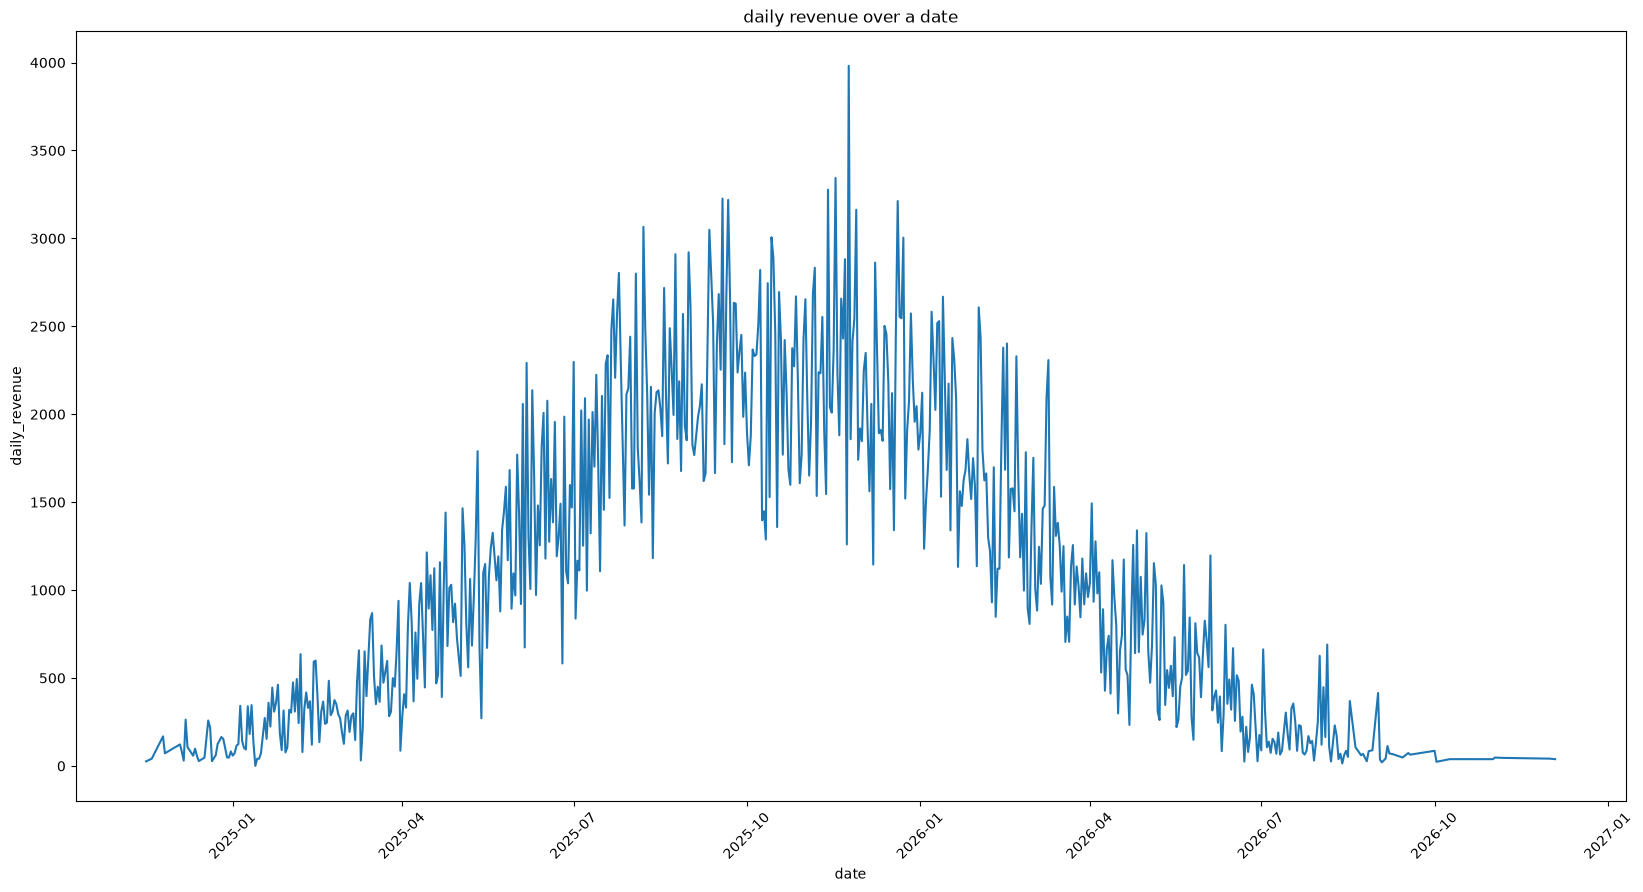

In [34]:
daily_revenue = daily_revenue.sort_index()
plt.figure(figsize=(20, 10))
plt.plot(daily_revenue.index, daily_revenue.astype(float))
plt.xlabel('date')
plt.xticks(rotation=45)
plt.ylabel('daily_revenue')
plt.title('daily revenue over a date')
plt.show()